# Evaluación 2: Clasificación de Razas de Gatos mediante Redes Convolucionales (CNN)

**Grupo 7**
- Agustín Fernández
- Sebastián Salgado
- Eduardo Uribe

**Asignatura:** Técnicas de Machine Learning I (TLY1102)  
**Fecha:** Octubre 2026  

---

## 1. Introducción

El presente proyecto aborda el desafío de clasificar automáticamente imágenes de 12 razas de gatos, utilizando una variante específica del Oxford-IIIT Pet Dataset. En la evaluación anterior, abordamos este problema mediante un Perceptrón Multicapa (MLP), logrando un desempeño base pero evidenciando las limitaciones de dicha arquitectura para datos no estructurados como imágenes.

El objetivo de esta segunda evaluación es implementar una Red Neuronal Convolucional (CNN). A diferencia del MLP, que requiere "aplanar" la imagen y destruir su topología espacial (perdiendo la relación entre píxeles adyacentes), la CNN preserva el formato matricial (2D o 3D con canales de color) y utiliza filtros (kernels) para extraer características locales y jerárquicas como bordes, texturas y formas complejas.

Resulta altamente pertinente comparar este nuevo modelo con el MLP desarrollado previamente para cuantificar objetivamente la mejora en el desempeño, la eficiencia en la cantidad de parámetros (gracias al uso de pesos compartidos) y la capacidad de generalización visual frente a clases complejas de felinos.

### Consideraciones éticas
- **Datos utilizados:** El dataset contiene imágenes de animales de acceso público, sin comprometer información personal.
- **Uso previsto:** Herramienta de apoyo a la identificación visual; las decisiones críticas siempre deben ser supervisadas por un experto.
- **Interpretabilidad:** Para asegurar la transparencia del modelo y evitar problemas de sesgo o "caja negra", se implementarán técnicas como la visualización de Feature Maps y mapas de activación (Grad-CAM), documentando en qué zonas de la imagen se enfoca el modelo para decidir.


### Variante desarrollada por el grupo
Se conserva la variante de la Evaluación 1:

| Decisión | Detalle | Justificación |
|---|---|---|
| Subconjunto | Solo gatos (SPECIES == 1): **12 razas**; se descartan los perros | Clasificación multiclase acotada y abordable en el tiempo de la evaluación. |
| Partición | 80 % entrenamiento / 20 % prueba por raza (seed 29); del 80 %, un 20 % para validación | Mantiene el balance de clases y es la misma partición del MLP, lo que permite comparar con equidad. |
| Resolución | 64 × 64 RGB | Misma entrada que el MLP: solo cambia la arquitectura. |

**imports**

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import os
import random
import shutil
import urllib.request
import zipfile
import json
from time import time

from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

np.random.seed(29)
random.seed(29)
tf.random.set_seed(29)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Preparación del conjunto de datos

Pasos del proceso:
1. **Descarga y partición:** igual que en la Evaluación 1; se filtran gatos, se organizan por raza y se separa 80 % / 20 % (entrenamiento / prueba).
2. **Conservación del formato matricial:** cada imagen es un tensor (64, 64, 3); no se aplana durante las capas convolucionales.
3. **Redimensionamiento:** 64 × 64 px, misma resolución que el MLP.
4. **Normalización:** división por 255 → rango [0, 1], lo que estabiliza el gradiente y acelera la convergencia.
5. **Validación:** 20 % del conjunto de entrenamiento, sin solapamiento con él.
6. **Visualización** de ejemplos representativos por raza.

> **Adaptación respecto a la Evaluación 1:** el MLP aplana la imagen (capa Flatten) antes de sus capas densas, por lo que solo ve un vector de 12.288 valores y no la vecindad entre píxeles. La CNN mantiene las imágenes como tensores (64, 64, 3) durante todas las capas convolucionales y solo las aplana al final, después de extraer características. Se conservan la misma resolución, normalización [0, 1] y partición (seed 29), y se agrega un conjunto de validación (20 % del entrenamiento) para monitorear el aprendizaje.
>
> **Corrección importante:** en la Evaluación 1 el conjunto de validación se creó con shuffle=False, lo que en Keras impide mezclar los archivos antes de dividir y hace que la validación se solape con el entrenamiento (por eso el MLP mostraba val_accuracy ≈ 0,47 frente a ≈ 0,26 en prueba). Aquí la validación usa shuffle=True con la misma seed que el entrenamiento y se verifica que no comparte imágenes.

In [35]:
DATASET_PATH = "../data"
MODELS_DIR = "../models"
os.makedirs(DATASET_PATH, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)


TRAIN_DIR = '../data/seg_train'
TEST_DIR = '../data/seg_test'
train_txt = '../data/annotations/annotations/trainval.txt'
test_txt = '../data/annotations/annotations/test.txt'
img_base_dir = '../data/images/images/'
IMAGES_DIR = '../images'
os.makedirs(IMAGES_DIR, exist_ok=True)

url_dataset = "https://www.dropbox.com/scl/fi/thq7rajv0nc4wxxleb19w/The-Oxford-IIIT-Pet-Dataset.zip?rlkey=7cxo4vsbolydcrk8qx33ox01w&st=0m51e1a9&dl=1"
url_mlp = "https://www.dropbox.com/scl/fi/bwvzsr3zg7d2wnen65kjg/mlp_model.keras?rlkey=4gegc45pnxwoz5wvjpa4wqa0h&st=9y9epvpu&dl=1"

archivo_mlp = os.path.join(MODELS_DIR, "mlp_model.keras")

def guardar(nombre):
    plt.savefig(f"{IMAGES_DIR}/{nombre}.png", dpi=150, bbox_inches="tight")

if not os.path.exists(train_txt) or not os.path.exists(img_base_dir):
    print("Dataset no encontrado. Descargando")
    zip_path = os.path.join(DATASET_PATH, "dataset.zip")
    urllib.request.urlretrieve(url_dataset, zip_path)
    print("Descomprimiendo archivos")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(DATASET_PATH)
    os.remove(zip_path)
else:
    print("El dataset ya existe en la carpeta")

if not os.path.exists(archivo_mlp):
    print("Descargando modelo MLP")
    urllib.request.urlretrieve(url_mlp, archivo_mlp)
    print("Modelo descargado exitosamente")
else:
    print("El modelo MLP ya existe en la carpeta")

El dataset ya existe en la carpeta
El modelo MLP ya existe en la carpeta


In [36]:
if not (os.path.exists(TRAIN_DIR) and len(os.listdir(TRAIN_DIR)) > 0):
    os.makedirs(TRAIN_DIR, exist_ok=True)
    os.makedirs(TEST_DIR, exist_ok=True)

    df_train = pd.read_csv(train_txt, sep=' ', header=None, comment='#', names=['Image', 'CLASS_ID', 'SPECIES', 'BREED_ID'])
    df_test = pd.read_csv(test_txt, sep=' ', header=None, comment='#', names=['Image', 'CLASS_ID', 'SPECIES', 'BREED_ID'])
    df_all = pd.concat([df_train, df_test], ignore_index=True)
    gatos = df_all[df_all['SPECIES'] == 1].copy()

    gatos['Raza'] = gatos['Image'].apply(lambda x: '_'.join(str(x).split('_')[:-1]))
    razas = gatos['Raza'].unique()

    print("80% Train / 20% Test")

    for raza in razas:
        os.makedirs(os.path.join(TRAIN_DIR, raza), exist_ok=True)
        os.makedirs(os.path.join(TEST_DIR, raza), exist_ok=True)

        imgs_raza = gatos[gatos['Raza'] == raza]['Image'].tolist()
        imgs_raza = [str(img) + '.jpg' for img in imgs_raza]

        np.random.shuffle(imgs_raza)
        split_idx = int(len(imgs_raza) * 0.8)
        train_imgs = imgs_raza[:split_idx]
        test_imgs = imgs_raza[split_idx:]

        for img_name in train_imgs:
            origen = os.path.join(img_base_dir, img_name)
            destino = os.path.join(TRAIN_DIR, raza, img_name)
            if os.path.exists(origen):
                shutil.copy(origen, destino)


        for img_name in test_imgs:
            origen = os.path.join(img_base_dir, img_name)
            destino = os.path.join(TEST_DIR, raza, img_name)
            if os.path.exists(origen):
                shutil.copy(origen, destino)

    print("Imagenes distribuidas")
else:
    print("Las imagenes ya fueron distribuidas")

Las imagenes ya fueron distribuidas


In [37]:
classes = sorted(os.listdir(TRAIN_DIR))

train_counts = {}
for class_name in classes:
    class_path = os.path.join(TRAIN_DIR, class_name)
    train_counts[class_name] = len(os.listdir(class_path))

test_counts = {}
for class_name in classes:
    class_path = os.path.join(TEST_DIR, class_name)
    test_counts[class_name] = len(os.listdir(class_path))

class_distribution = pd.DataFrame({
    "razas": classes,
    "Training": [train_counts[c] for c in classes],
    "Testing": [test_counts[c] for c in classes]
})

display(class_distribution)

,razas,Training,Testing
0,Abyssinian,158,40
1,Bengal,160,40
2,Birman,160,40
3,Bombay,147,37
4,British_Shorthair,160,40
5,Egyptian_Mau,152,38
6,Maine_Coon,160,40
7,Persian,160,40
8,Ragdoll,160,40
9,Russian_Blue,160,40


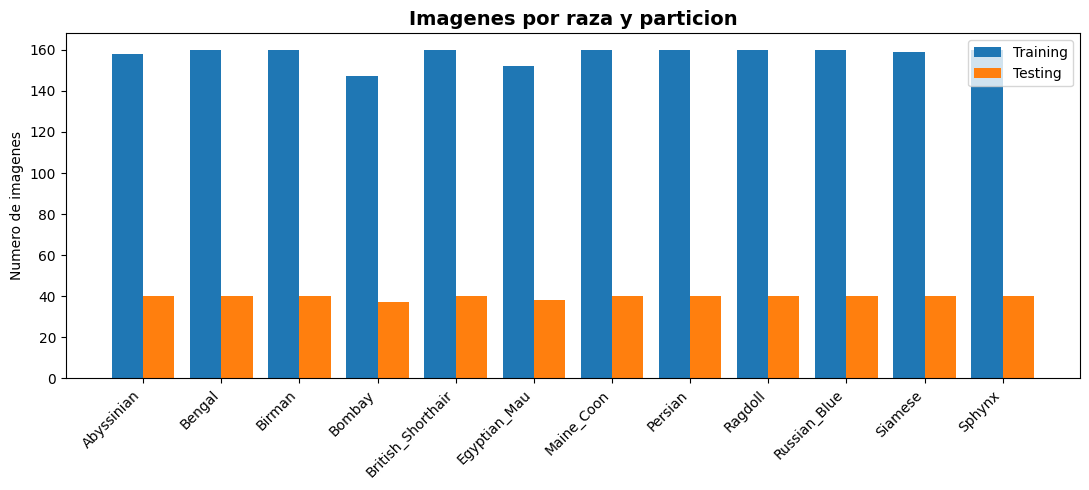

In [38]:
x = np.arange(len(classes))
plt.figure(figsize=(11, 5))
plt.bar(x - 0.2, class_distribution["Training"], width=0.4, label="Training")
plt.bar(x + 0.2, class_distribution["Testing"], width=0.4, label="Testing")
plt.xticks(x, classes, rotation=45, ha="right")
plt.title("Imagenes por raza y particion", fontsize=14, fontweight="bold")
plt.ylabel("Numero de imagenes")
plt.legend()
plt.tight_layout()
guardar("01_distribucion_clases")
plt.show()

In [39]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 32
EPOCHS = 30

In [40]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=29,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=True)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=29,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=True)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)

classes = train_ds.class_names
NUM_CLASSES = len(classes)

def ds_to_arrays(ds):
    X, y = [], []
    for imgs, labs in ds:
        X.append(imgs.numpy())
        y.append(labs.numpy())
    X = np.concatenate(X, axis=0).astype("float32") / 255.0
    y = np.concatenate(y, axis=0)
    return X, y

X_train, y_train = ds_to_arrays(train_ds)
X_val, y_val = ds_to_arrays(val_ds)
X_test, y_test = ds_to_arrays(test_ds)

print(f"Entrenamiento: {X_train.shape} | Validacion: {X_val.shape} | Test: {X_test.shape}")

Found 1896 files belonging to 12 classes.
Using 1517 files for training.
Found 1896 files belonging to 12 classes.
Using 379 files for validation.
Found 475 files belonging to 12 classes.
Entrenamiento: (1517, 64, 64, 3) | Validacion: (379, 64, 64, 3) | Test: (475, 64, 64, 3)


**2.1 Verificación de la partición:** entrenamiento y validación no deben compartir archivos.

In [41]:
train_files = set(train_ds.file_paths)
val_files = set(val_ds.file_paths)
print(f"Archivos en entrenamiento: {len(train_files)} | en validacion: {len(val_files)}")
print("Sin solapamiento:", train_files.isdisjoint(val_files))
assert train_files.isdisjoint(val_files), "Hay imagenes compartidas entre entrenamiento y validacion"


Archivos en entrenamiento: 1517 | en validacion: 379
Sin solapamiento: True


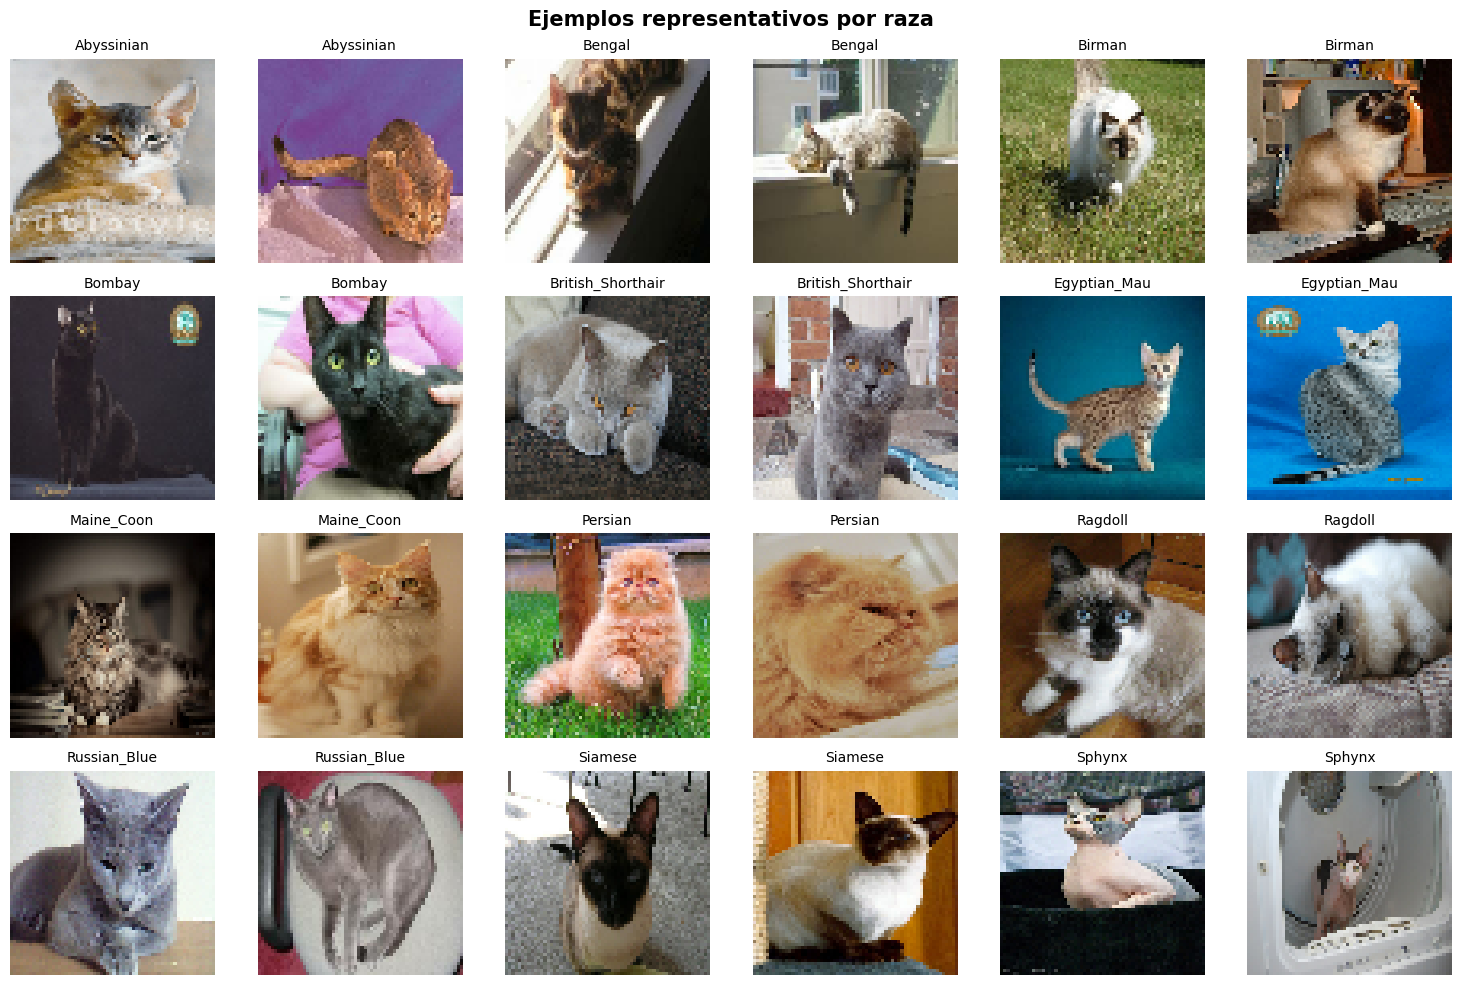

In [42]:
fig, axs = plt.subplots(4, 6, figsize=(15, 10))
for i, ax in enumerate(axs.flat):
    clase = i // 2
    idxs = np.where(y_train == clase)[0]
    ax.imshow(X_train[idxs[i % 2]])
    ax.set_title(classes[clase], fontsize=10)
    ax.axis("off")
plt.suptitle("Ejemplos representativos por raza", fontsize=15, fontweight="bold")
plt.tight_layout()
guardar("02_ejemplos_por_raza")
plt.show()

## 3. Diseño de la Red Neuronal Convolucional

Arquitectura: 3 bloques Conv + MaxPooling seguidos de un clasificador denso.

| Componente | Decisión | Justificación técnica |
|---|---|---|
| Capas convolucionales | 3 (16 → 32 → 64 filtros) | Permiten una jerarquía bordes/colores → texturas → partes (orejas, ojos). Se usan pocos filtros porque con ~1.500 imágenes una red más grande memoriza con facilidad. |
| Tamaño de filtro | 3 × 3| Kernels pequeños apilados tienen un campo receptivo amplio con pocos parámetros. |
| Activación | ReLU en capas ocultas | No satura para valores positivos (evita desvanecimiento del gradiente) y es barata de calcular. |
| Pooling | MaxPooling 2 × 2 tras cada convolución | Reduce a la mitad el alto y ancho, disminuye parámetros y da invarianza a pequeñas traslaciones; conserva el rasgo más intenso de cada ventana. |
| Capa de aplanado | Flatten (64 × 6 × 6 = 2.304 valores) | Pasa del mapa de características al clasificador. Con solo 3 pooling el mapa final es de 6 × 6. |
| Capa densa | 128 neuronas, ReLU | Combina las características extraídas; tamaño moderado para limitar la capacidad de memorizar. |
| Salida | 12 neuronas, softmax | Distribución de probabilidad sobre las 12 razas (multiclase excluyente). |
| Pérdida | sparse_categorical_crossentropy | Etiquetas enteras (0–11) y salida softmax; evita convertir a one-hot. |
| Optimizador | Adam | Tasa adaptativa por parámetro; converge rápido sin ajuste fino. |
| Batch size | 32 | Compromiso entre estabilidad del gradiente y memoria; ~48 iteraciones por época con 1.517 imágenes. |
| Épocas / parada | Máximo 30 con EarlyStopping | Detiene el entrenamiento cuando la pérdida de validación deja de mejorar y conserva los mejores pesos. |

**Dimensiones:** 64×64 → Conv 62×62 → Pool 31×31 → Conv 29×29 → Pool 14×14 → Conv 12×12 → Pool 6×6 → Flatten 2.304 → Dense 128 → Salida 12. Total: 320.172 parámetros.

In [43]:
cnn_model = keras.models.Sequential([
    keras.layers.Input(shape=(64, 64, 3), name="Entrada"),

    keras.layers.Conv2D(16, (3, 3), activation="relu", name="Convolucion_1"),
    keras.layers.MaxPooling2D((2, 2), name="Pooling_1"),

    keras.layers.Conv2D(32, (3, 3), activation="relu", name="Convolucion_2"),
    keras.layers.MaxPooling2D((2, 2), name="Pooling_2"),

    keras.layers.Conv2D(64, (3, 3), activation="relu", name="Convolucion_3"),
    keras.layers.MaxPooling2D((2, 2), name="Pooling_3"),

    keras.layers.Flatten(name="Aplanado"),
    keras.layers.Dense(128, activation="relu", name="Densa_1"),
    keras.layers.Dense(NUM_CLASSES, activation="softmax", name="Salida"),
], name="CNN_Gatos")

cnn_model.summary()

Model: "CNN_Gatos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Convolucion_1 (Conv2D)          │ (None, 62, 62, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_1 (MaxPooling2D)        │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolucion_2 (Conv2D)          │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_2 (MaxPooling2D)        │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolucion_3 (Conv2D)          │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_3 (MaxPooling2D)        │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Aplanado (Flatten)              │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa_1 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Salida (Dense)                  │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,172 (1.22 MB)

 Trainable params: 320,172 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Entrenamiento del Modelo CNN

Se compila con Adam ysparse_categorical_crossentropy. Se registra el tiempo de entrenamiento para la comparación con el MLP y se guarda el modelo en models.

In [44]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [45]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

t0 = time()
history_cnn = cnn_model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    callbacks=[early_stop]
)
t_cnn = time() - t0
print(f"Epocas ejecutadas: {len(history_cnn.history['loss'])} | Tiempo: {t_cnn:.1f} s")

Epoch 1/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.1404 - loss: 2.4447 - val_accuracy: 0.1425 - val_loss: 2.3500
Epoch 2/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.2452 - loss: 2.1678 - val_accuracy: 0.2454 - val_loss: 2.1967
Epoch 3/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.3217 - loss: 1.9423 - val_accuracy: 0.3087 - val_loss: 2.1420
Epoch 4/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.3784 - loss: 1.7813 - val_accuracy: 0.3166 - val_loss: 2.0841
Epoch 5/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.4377 - loss: 1.6429 - val_accuracy: 0.3430 - val_loss: 2.0570
Epoch 6/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.4654 - loss: 1.5296 - val_accuracy: 0.3562 - val_loss: 2.0576
Epoch 7/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.5221 - loss: 1.3834 - val_accuracy: 0.3219 - val_loss: 2.0782
Epoch 8/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.5854 - loss: 1.2138 - val_accuracy: 0.3404 - v

In [46]:
cnn_model.save(os.path.join(MODELS_DIR, "cnn_model.keras"))
print("Modelo CNN guardado en", os.path.join(MODELS_DIR, "cnn_model.keras"))

Modelo CNN guardado en ../models\cnn_model.keras


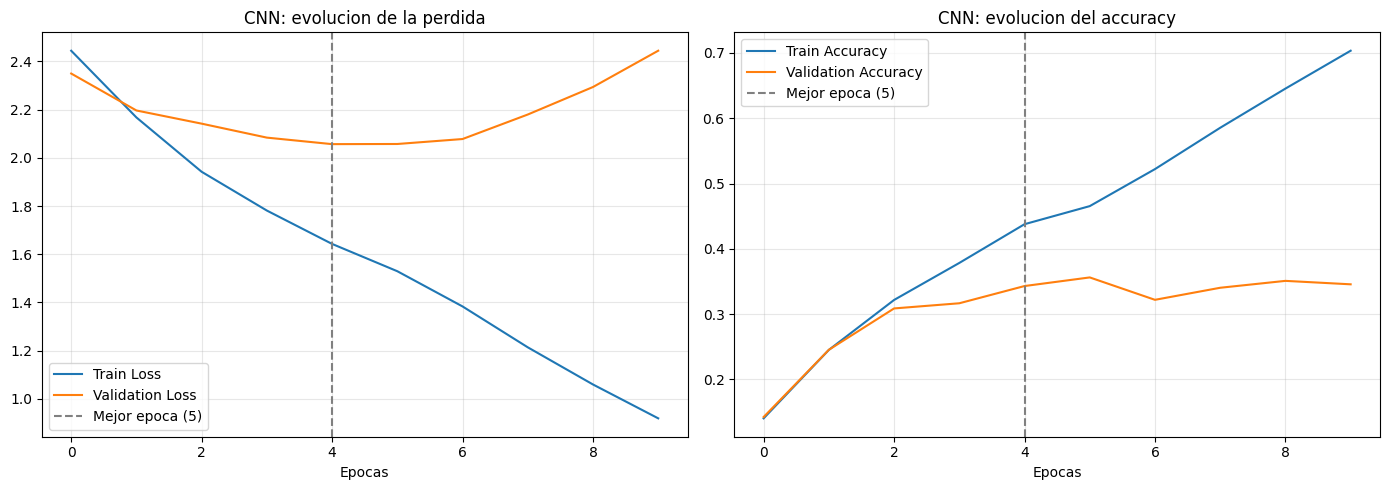

Epocas ejecutadas: 10 de 30| Tiempo: 10.0 s
Mejor val_loss: 2.057 en la epoca 5 (train_acc = 0.438 | val_acc = 0.343)
Última epoca ejecutada -> train_acc = 0.703 | val_acc = 0.346 | val_loss = 2.445
Brecha train-val (accuracy) en la ultima epoca: 0.358
El modelo final usa los pesos de la mejor epoca.


In [47]:
def graficar_curvas(history, nombre, titulo):
    mejor = int(np.argmin(history.history["val_loss"]))
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    axs[0].plot(history.history["loss"], label="Train Loss")
    axs[0].plot(history.history["val_loss"], label="Validation Loss")
    axs[0].axvline(mejor, color="gray", ls="--", label=f"Mejor epoca ({mejor+1})")
    axs[0].set_title(f"{titulo}: evolucion de la perdida")
    axs[0].set_xlabel("Epocas"); axs[0].legend(); axs[0].grid(True, alpha=0.3)

    axs[1].plot(history.history["accuracy"], label="Train Accuracy")
    axs[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
    axs[1].axvline(mejor, color="gray", ls="--", label=f"Mejor epoca ({mejor+1})")
    axs[1].set_title(f"{titulo}: evolucion del accuracy")
    axs[1].set_xlabel("Epocas"); axs[1].legend(); axs[1].grid(True, alpha=0.3)
    plt.tight_layout()
    guardar(nombre)
    plt.show()

graficar_curvas(history_cnn, "03_curvas_cnn", "CNN")

h = history_cnn.history
n_ep = len(h["loss"])
mejor_ep = int(np.argmin(h["val_loss"]))
print(f"Epocas ejecutadas: {n_ep} de {EPOCHS}| Tiempo: {t_cnn:.1f} s")
print(f"Mejor val_loss: {h['val_loss'][mejor_ep]:.3f} en la epoca {mejor_ep+1} "
      f"(train_acc = {h['accuracy'][mejor_ep]:.3f} | val_acc = {h['val_accuracy'][mejor_ep]:.3f})")
print(f"Última epoca ejecutada -> train_acc = {h['accuracy'][-1]:.3f} | val_acc = {h['val_accuracy'][-1]:.3f} | val_loss = {h['val_loss'][-1]:.3f}")
print(f"Brecha train-val (accuracy) en la ultima epoca: {h['accuracy'][-1] - h['val_accuracy'][-1]:.3f}")
print("El modelo final usa los pesos de la mejor epoca.")

**Análisis de las curvas**

- La pérdida y el accuracy de entrenamiento mejoran de forma sostenida: la red tiene capacidad para ajustarse al conjunto de entrenamiento.
- La pérdida de validación llega a un mínimo en las primeras épocas y después vuelve a subir mientras la de entrenamiento sigue bajando, y el accuracy de validación se estanca. Es la señal clásica de sobreajuste (overfitting): la brecha entre entrenamiento y validación crece con las épocas.
- EarlyStopping detuvo el entrenamiento antes de las 30 épocas (5 épocas sin mejorar val_loss) y restauró los pesos de la mejor época, limitando el sobreajuste sin agregar capas.
- Con ~1.500 imágenes de entrenamiento, 12 clases de grano fino y sin regularización ni augmentation, este comportamiento es esperable. La validación no comparte imágenes con el entrenamiento, por lo que sus curvas son una estimación honesta de la generalización.

## 5. Evaluación del modelo

Se evalúa en el conjunto de prueba con Accuracy, Precision, Recall, F1-Score y matriz de confusión.

In [48]:
def calcular_metricas(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

y_pred_cnn_probs = cnn_model.predict(X_test, verbose=0)
y_pred_cnn = np.argmax(y_pred_cnn_probs, axis=1)
met_cnn = calcular_metricas(y_test, y_pred_cnn)

print("================ REPORTE DE CLASIFICACION (CNN) ================")
print(classification_report(y_test, y_pred_cnn, target_names=classes, zero_division=0))

with open(f"{IMAGES_DIR}/reporte_clasificacion_cnn.txt", "w", encoding="utf-8") as f_rep:
    f_rep.write(classification_report(y_test, y_pred_cnn, target_names=classes, zero_division=0))

================ REPORTE DE CLASIFICACION (CNN) ================
                   precision    recall  f1-score   support

       Abyssinian       0.21      0.20      0.21        40
           Bengal       0.44      0.60      0.51        40
           Birman       0.57      0.20      0.30        40
           Bombay       0.56      0.95      0.71        37
British_Shorthair       0.34      0.42      0.38        40
     Egyptian_Mau       0.64      0.24      0.35        38
       Maine_Coon       0.38      0.25      0.30        40
          Persian       0.45      0.23      0.30        40
          Ragdoll       0.44      0.35      0.39        40
     Russian_Blue       0.50      0.12      0.20        40
          Siamese       0.31      0.50      0.38        40
           Sphynx       0.17      0.38      0.23        40

         accuracy                           0.37       475
        macro avg       0.42      0.37      0.35       475
     weighted avg       0.42      0.37      0.35

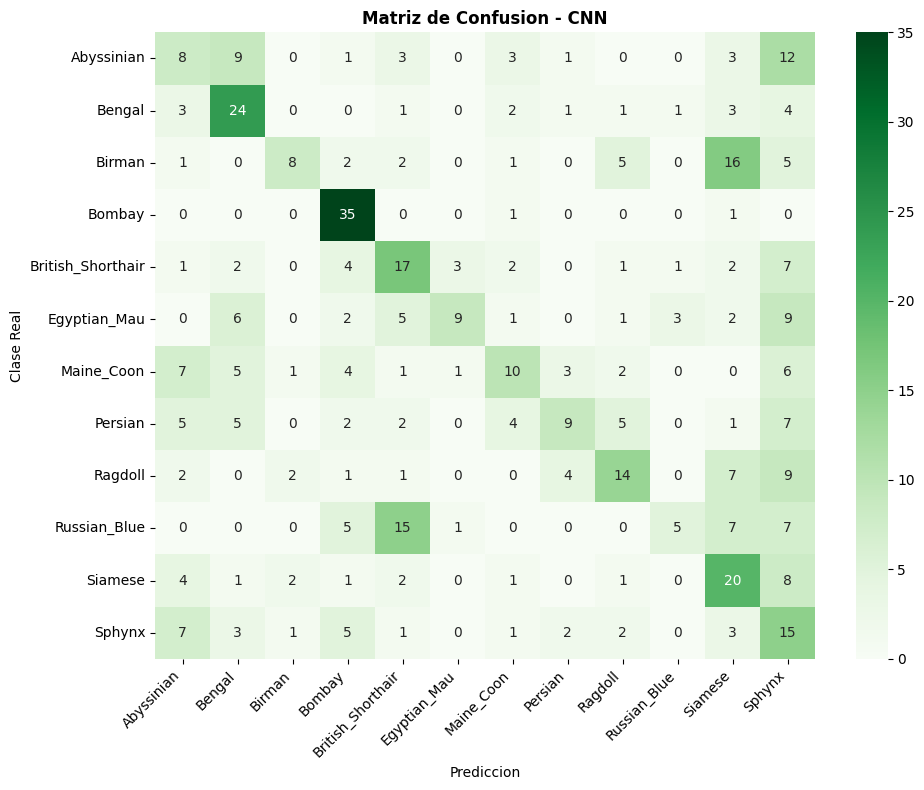

In [49]:
cm_cnn = confusion_matrix(y_test, y_pred_cnn)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm_cnn, annot=True, fmt="d", cmap="Greens", xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_title("Matriz de Confusion - CNN", fontweight="bold")
ax.set_ylabel("Clase Real"); ax.set_xlabel("Prediccion")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
guardar("04_matriz_confusion_cnn")
plt.show()

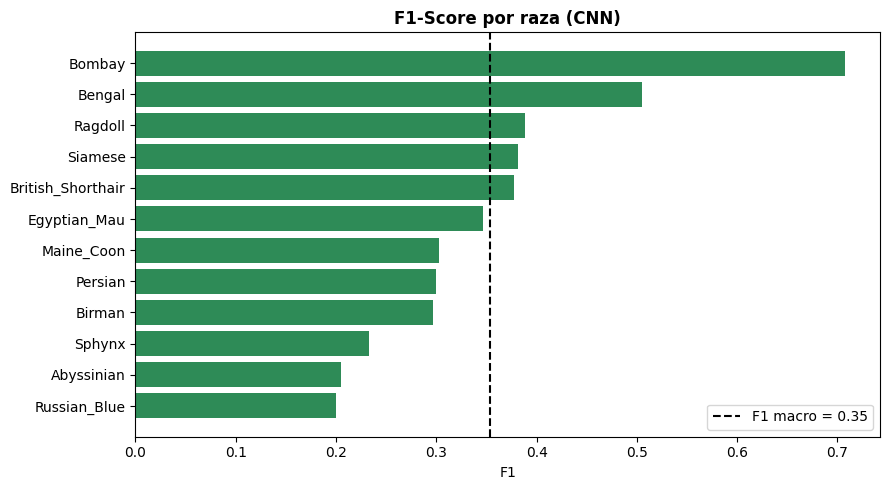

In [50]:

f1_cls = f1_score(y_test, y_pred_cnn, average=None, zero_division=0)
orden = np.argsort(f1_cls)
plt.figure(figsize=(9, 5))
plt.barh([classes[i] for i in orden], f1_cls[orden], color="seagreen")
plt.axvline(met_cnn["f1_macro"], color="k", ls="--", label=f"F1 macro = {met_cnn['f1_macro']:.2f}")
plt.title("F1-Score por raza (CNN)", fontweight="bold"); plt.xlabel("F1"); plt.legend()
plt.tight_layout()
guardar("05_f1_por_clase_cnn")
plt.show()

In [51]:
cm_off = cm_cnn.copy(); np.fill_diagonal(cm_off, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm_off.ravel())[:6], cm_off.shape))[0]
print("Confusiones mas frecuentes (real -> predicho):")
for r, p in top:
    print(f"  {classes[r]:18s} -> {classes[p]:18s}: {cm_off[r, p]} imagenes")

print(f"\nMejor raza : {classes[orden[-1]]} (F1 = {f1_cls[orden[-1]]:.2f})")
print(f"Peor raza  : {classes[orden[0]]} (F1 = {f1_cls[orden[0]]:.2f})")

Confusiones mas frecuentes (real -> predicho):
  Birman             -> Siamese           : 16 imagenes
  Russian_Blue       -> British_Shorthair : 15 imagenes
  Abyssinian         -> Sphynx            : 12 imagenes
  Abyssinian         -> Bengal            : 9 imagenes
  Egyptian_Mau       -> Sphynx            : 9 imagenes
  Ragdoll            -> Sphynx            : 9 imagenes

Mejor raza : Bombay (F1 = 0.71)
Peor raza  : Russian_Blue (F1 = 0.20)


**Interpretación de las métricas**

- **Accuracy y F1 macro** son similares porque el conjunto de prueba está casi balanceado (≈ 40 imágenes por raza); no hay una clase mayoritaria que infle el accuracy.
- El accuracy de prueba es claramente mayor que el azar (≈ 8,3 %) pero menor que el de entrenamiento: la brecha confirma el sobreajuste observado en las curvas. El modelo aprende rasgos específicos de las imágenes de entrenamiento que no generalizan por completo.
- Las razas con rasgos muy distintivos (en la ejecución de referencia, Bombay, de pelaje negro uniforme) alcanzan mayor F1; las razas de aspecto parecido se confunden entre sí, como muestran los pares más confundidos de la celda anterior y la matriz de confusión.
- Con imágenes de solo 64 × 64 px se pierde detalle fino de textura del pelaje, que es justamente lo que diferencia a varias razas; esto limita el techo de desempeño.

## 6. Comparación entre MLP y CNN

La comparación se hace contra el MLP ya entregado en la Evaluación 1, sin reentrenarlo. Ese modelo se carga y se evalúa sobre el mismo conjunto de prueba que la CNN, con la misma resolución (64 × 64) y normalización [0, 1]. Los conjuntos de entrenamiento coinciden (misma seed y shuffle=True).

**Diferencias de entrenamiento que deben tenerse presentes:**

| | MLP (Evaluación 1) | CNN (Evaluación 2) |
|---|---|---|
| Optimizador | SGD | Adam |
| Pérdida | categorical_crossentropy | sparse_categorical_crossentropy |
| EarlyStopping | patience=5 (no se activó: 30 épocas) | patience=5 (se detuvo antes de las 30) |
| Validación | Con shuffle=true | shuffle=True, sin solapamiento |

>La comparación se hace con el conjunto de prueba, que ninguno de los dos modelos vio. Aquí también se reevalúa el MLP sobre la validación limpia de esta evaluación.

Como el modelo guardado no entrega sus curvas, el tiempo de entrenamiento del MLP se toma del registro de la Evaluación 1 (11,48 s para 30 épocas).

La accuracy de prueba del MLP se recalcula sobre la partición actual (0,269), que difiere levemente de la registrada en la Evaluación 1 (0,259). Se usa la recalculada, porque es la que permite comparar ambos modelos sobre exactamente el mismo conjunto.

In [52]:
try:
    mlp_model = keras.models.load_model(archivo_mlp)
except Exception as e:
    raise RuntimeError(
        "No se pudo cargar models/mlp_model.keras"
    ) from e
mlp_model.summary()


Model: "RedE1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ primera_capa (Dense)            │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ segunda_capa (Dense)            │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_de_salida (Dense)          │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,582,030 (6.03 MB)

 Trainable params: 1,582,028 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [53]:
TIEMPO_MLP_E1_S = 11.48
EPOCAS_MLP_E1 = 30
ACC_MLP_E1_REGISTRADO = 0.2589

y_pred_mlp_probs = mlp_model.predict(X_test, verbose=0)
y_pred_mlp = np.argmax(y_pred_mlp_probs, axis=1)
met_mlp = calcular_metricas(y_test, y_pred_mlp)

acc_mlp_train = accuracy_score(y_train, np.argmax(mlp_model.predict(X_train, verbose=0), axis=1))
acc_mlp_val = accuracy_score(y_val, np.argmax(mlp_model.predict(X_val, verbose=0), axis=1))
acc_cnn_train = accuracy_score(y_train, np.argmax(cnn_model.predict(X_train, verbose=0), axis=1))
acc_cnn_val = accuracy_score(y_val, np.argmax(cnn_model.predict(X_val, verbose=0), axis=1))
print(f"MLP -> train: {acc_mlp_train:.3f} | val: {acc_mlp_val:.3f} | test: {met_mlp['accuracy']:.3f}")
print(f"CNN -> train: {acc_cnn_train:.3f} | val: {acc_cnn_val:.3f} | test: {met_cnn['accuracy']:.3f}")

MLP -> train: 0.247 | val: 0.135 | test: 0.194
CNN -> train: 0.465 | val: 0.343 | test: 0.366


In [54]:

n_ep_cnn = len(history_cnn.history["loss"])

def fila(nombre, met, params, epocas, tiempo, a_tr, a_val):
    return {
        "Modelo": nombre,
        "Accuracy": met["accuracy"], "Precision (macro)": met["precision_macro"],
        "Recall (macro)": met["recall_macro"], "F1 (macro)": met["f1_macro"],
        "Parámetros": params,
        "Épocas": epocas, "Tiempo entren. (s)": tiempo, "Tiempo/época (s)": tiempo / epocas,
        "Acc. train": a_tr, "Acc. val": a_val,
    }

df_comp = pd.DataFrame([
    fila("MLP", met_mlp, mlp_model.count_params(), EPOCAS_MLP_E1, TIEMPO_MLP_E1_S, acc_mlp_train, acc_mlp_val),
    fila("CNN", met_cnn, cnn_model.count_params(), n_ep_cnn, t_cnn, acc_cnn_train, acc_cnn_val),
]).set_index("Modelo")
df_comp["Acc. test"] = df_comp["Accuracy"]
df_comp["Brecha train-test"] = df_comp["Acc. train"] - df_comp["Acc. test"]
display(df_comp.style.format({
    "Accuracy": "{:.3f}", "Precision (macro)": "{:.3f}", "Recall (macro)": "{:.3f}", "F1 (macro)": "{:.3f}",
    "Parámetros": "{:,.0f}", "Épocas": "{:.0f}", "Tiempo entren. (s)": "{:.1f}", "Tiempo/época (s)": "{:.2f}",
    "Acc. train": "{:.3f}", "Acc. val": "{:.3f}", "Acc. test": "{:.3f}", "Brecha train-test": "{:.3f}"}))

df_comp.to_csv(f"{IMAGES_DIR}/tabla_comparacion.csv")

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Parámetros,Épocas,Tiempo entren. (s),Tiempo/época (s),Acc. train,Acc. val,Acc. test,Brecha train-test
Modelo,,,,,,,,,,,,
MLP,0.194,0.218,0.196,0.156,"1,582,028",30,11.5,0.38,0.247,0.135,0.194,0.054
CNN,0.366,0.418,0.369,0.354,"320,172",10,10.0,1.00,0.465,0.343,0.366,0.098


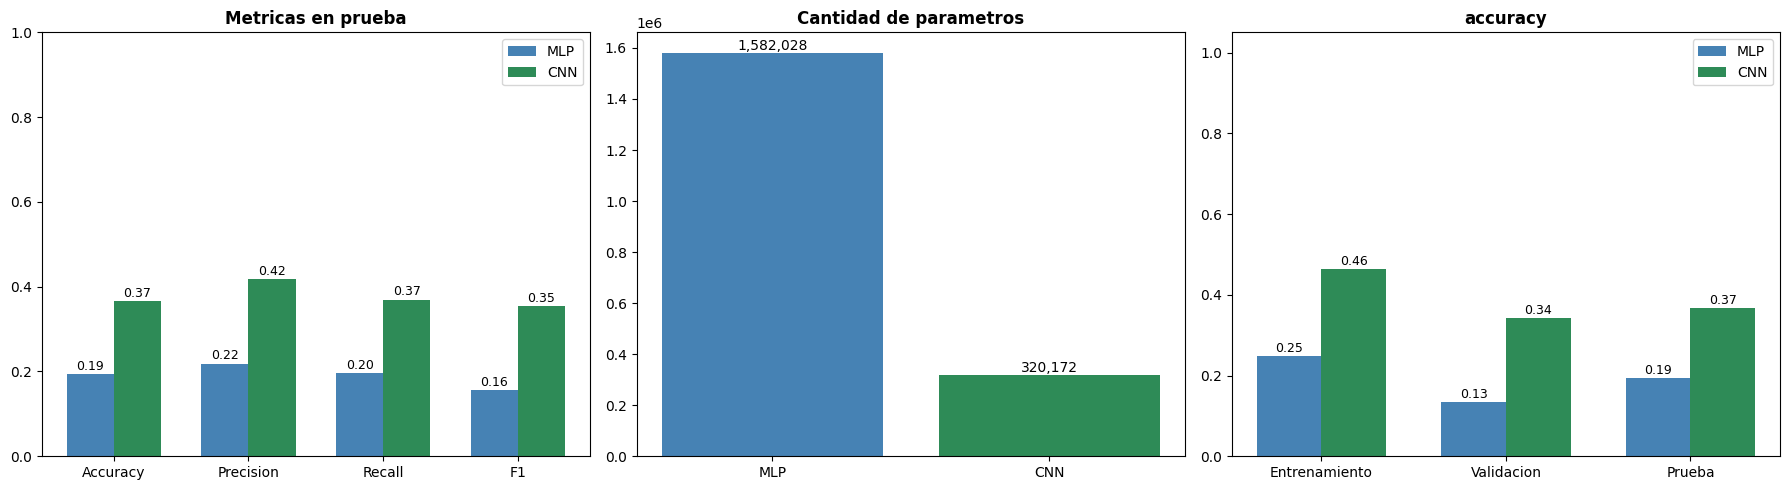

In [55]:

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

met_names = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
etiquetas = ["Accuracy", "Precision", "Recall", "F1"]
w = 0.35
xx = np.arange(len(met_names))
axs[0].bar(xx - w/2, [met_mlp[m] for m in met_names], w, label="MLP", color="steelblue")
axs[0].bar(xx + w/2, [met_cnn[m] for m in met_names], w, label="CNN", color="seagreen")
axs[0].set_xticks(xx); axs[0].set_xticklabels(etiquetas)
axs[0].set_ylim(0, 1); axs[0].set_title("Metricas en prueba", fontweight="bold"); axs[0].legend()
for i, m in enumerate(met_names):
    axs[0].text(i - w/2, met_mlp[m] + 0.01, f"{met_mlp[m]:.2f}", ha="center", fontsize=9)
    axs[0].text(i + w/2, met_cnn[m] + 0.01, f"{met_cnn[m]:.2f}", ha="center", fontsize=9)


pars = [mlp_model.count_params(), cnn_model.count_params()]
axs[1].bar(["MLP", "CNN"], pars, color=["steelblue", "seagreen"])
axs[1].set_title("Cantidad de parametros", fontweight="bold")
for i, v in enumerate(pars):
    axs[1].text(i, v, f"{v:,}", ha="center", va="bottom")

gx = np.arange(3)
vm = [acc_mlp_train, acc_mlp_val, met_mlp["accuracy"]]
vc = [acc_cnn_train, acc_cnn_val, met_cnn["accuracy"]]
axs[2].bar(gx - w/2, vm, w, label="MLP", color="steelblue")
axs[2].bar(gx + w/2, vc, w, label="CNN", color="seagreen")
axs[2].set_xticks(gx); axs[2].set_xticklabels(["Entrenamiento", "Validacion", "Prueba"])
axs[2].set_ylim(0, 1.05); axs[2].set_title("accuracy", fontweight="bold"); axs[2].legend()
for i, (m_, c_) in enumerate(zip(vm, vc)):
    axs[2].text(i - w/2, m_ + 0.01, f"{m_:.2f}", ha="center", fontsize=9)
    axs[2].text(i + w/2, c_ + 0.01, f"{c_:.2f}", ha="center", fontsize=9)

plt.tight_layout()
guardar("06_comparacion_barras")
plt.show()

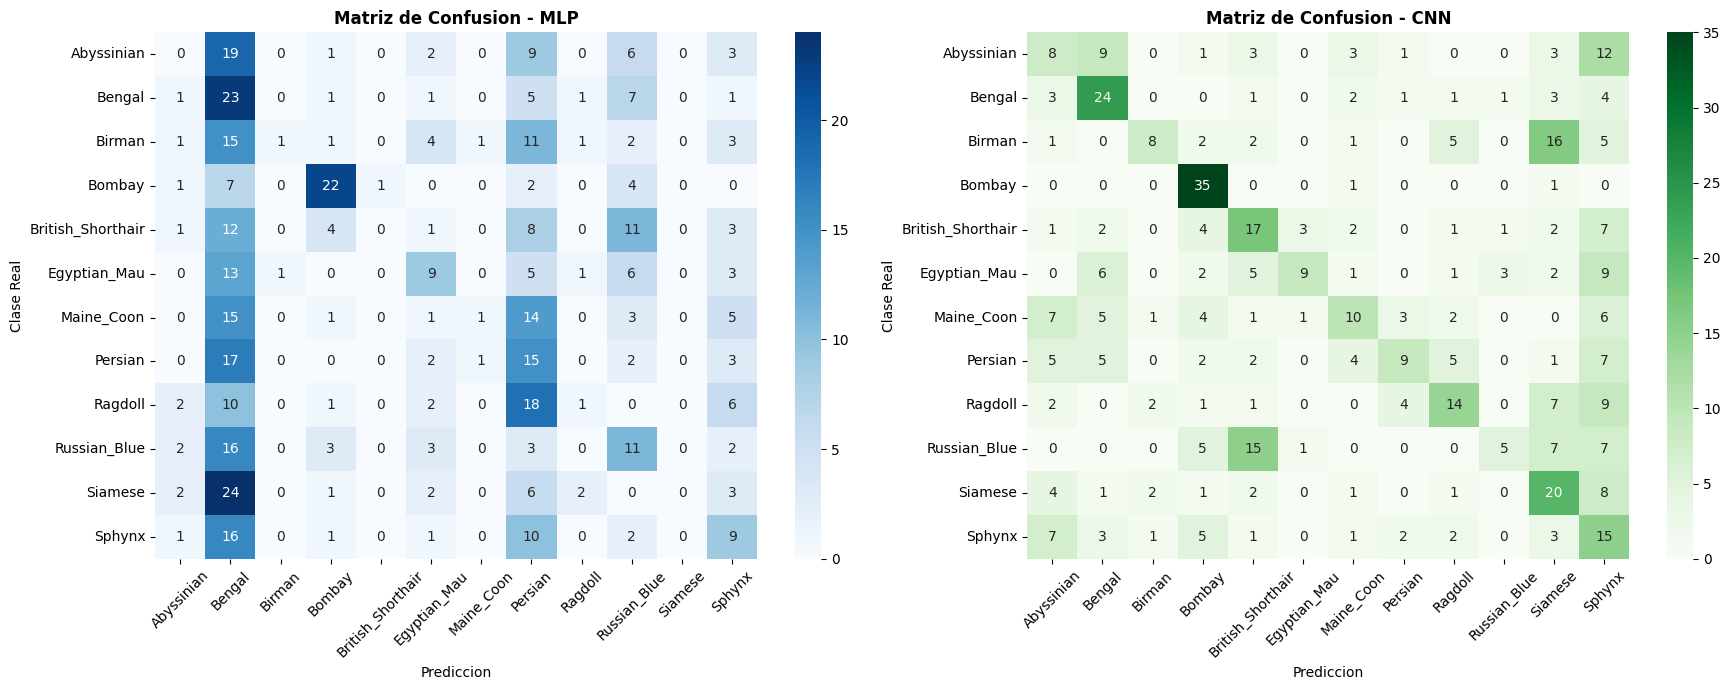

In [56]:

fig, axs = plt.subplots(1, 2, figsize=(18, 7))
cm_mlp = confusion_matrix(y_test, y_pred_mlp)
sns.heatmap(cm_mlp, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=axs[0])
axs[0].set_title("Matriz de Confusion - MLP", fontweight="bold")
sns.heatmap(cm_cnn, annot=True, fmt="d", cmap="Greens", xticklabels=classes, yticklabels=classes, ax=axs[1])
axs[1].set_title("Matriz de Confusion - CNN", fontweight="bold")
for a in axs:
    a.set_ylabel("Clase Real"); a.set_xlabel("Prediccion"); a.tick_params(axis="x", rotation=45)
plt.tight_layout()
guardar("07_matrices_confusion_comparacion")
plt.show()



In [57]:
f1_mlp_cls = f1_score(y_test, y_pred_mlp, average=None, zero_division=0)
dif = pd.DataFrame({"Raza": classes, "F1 MLP": f1_mlp_cls, "F1 CNN": f1_cls, "Δ (CNN - MLP)": f1_cls - f1_mlp_cls})
display(dif.round(3).sort_values("Δ (CNN - MLP)", ascending=False).reset_index(drop=True))

,Raza,F1 MLP,F1 CNN,Δ (CNN - MLP)
0,Siamese,0.000,0.381,0.381
1,British_Shorthair,0.000,0.378,0.378
2,Ragdoll,0.043,0.389,0.345
3,Bengal,0.203,0.505,0.303
4,Maine_Coon,0.047,0.303,0.257
5,Birman,0.048,0.296,0.249
6,Abyssinian,0.000,0.205,0.205
7,Bombay,0.603,0.707,0.104
8,Persian,0.205,0.300,0.095
9,Egyptian_Mau,0.273,0.346,0.073


**Ventajas y desventajas**

| | MLP | CNN |
|---|---|---|
| **Ventajas** | Simple, muy rápido de entrenar, fácil de implementar. | Preserva la estructura espacial; los filtros con pesos compartidos detectan el mismo patrón en cualquier posición; extrae características jerárquicas automáticamente; es interpretable mediante Feature Maps y Grad-CAM. |
| **Desventajas** | Aplana la imagen y pierde la vecindad entre píxeles; no es invariante a traslaciones; casi todos sus parámetros están en la primera capa densa (12.288 × 128 ≈ 1,57 M); generaliza peor. | Mayor costo de cómputo por época; más decisiones de diseño; con pocos datos y sin regularización sobreajusta y depende de la resolución de entrada. |

**Lectura de la evidencia** (tabla y gráficos de arriba):
- **Desempeño:** la CNN supera al MLP en Accuracy, Precision, Recall y F1 en el conjunto de prueba.
- **Parámetros:** la CNN usa muchos menos parámetro que el MLP gracias a los pesos compartidos, y aun así rinde mejor.
- **Tiempo:** el MLP tarda menos por época; la CNN requiere más operaciones por las convoluciones aunque tenga menos parámetros. Los tiempos totales no son estrictamente comparables porque cada modelo se entrenó con distinta cantidad de épocas y en ejecuciones distintas, por eso se incluye también el tiempo por época.
- **Generalización:** ambos modelos rinden menos en prueba que en entrenamiento; la brecha train-test de la tabla cuantifica el sobreajuste de cada uno. La CNN conserva ventaja en prueba.

### 6.5 Análisis de ejemplos correctos e incorrectos (CNN vs MLP)
Se muestran predicciones correctas e incorrectas de la CNN con su confianza y la predicción del MLP sobre la misma imagen.

In [58]:
rng = np.random.default_rng(29)
conf_cnn = y_pred_cnn_probs.max(axis=1)
idx_ok = np.where(y_pred_cnn == y_test)[0]
idx_err = np.where(y_pred_cnn != y_test)[0]

print(f"Aciertos CNN: {len(idx_ok)} | Errores CNN: {len(idx_err)}")
print(f"Confianza media en aciertos: {conf_cnn[idx_ok].mean():.2f} | en errores: {conf_cnn[idx_err].mean():.2f}")
print(f"Imágenes que la CNN acierta y el MLP falla: {np.sum((y_pred_cnn == y_test) & (y_pred_mlp != y_test))}")
print(f"Imágenes que el MLP acierta y la CNN falla: {np.sum((y_pred_cnn != y_test) & (y_pred_mlp == y_test))}")

Aciertos CNN: 174 | Errores CNN: 301
Confianza media en aciertos: 0.53 | en errores: 0.39
Imágenes que la CNN acierta y el MLP falla: 113
Imágenes que el MLP acierta y la CNN falla: 31


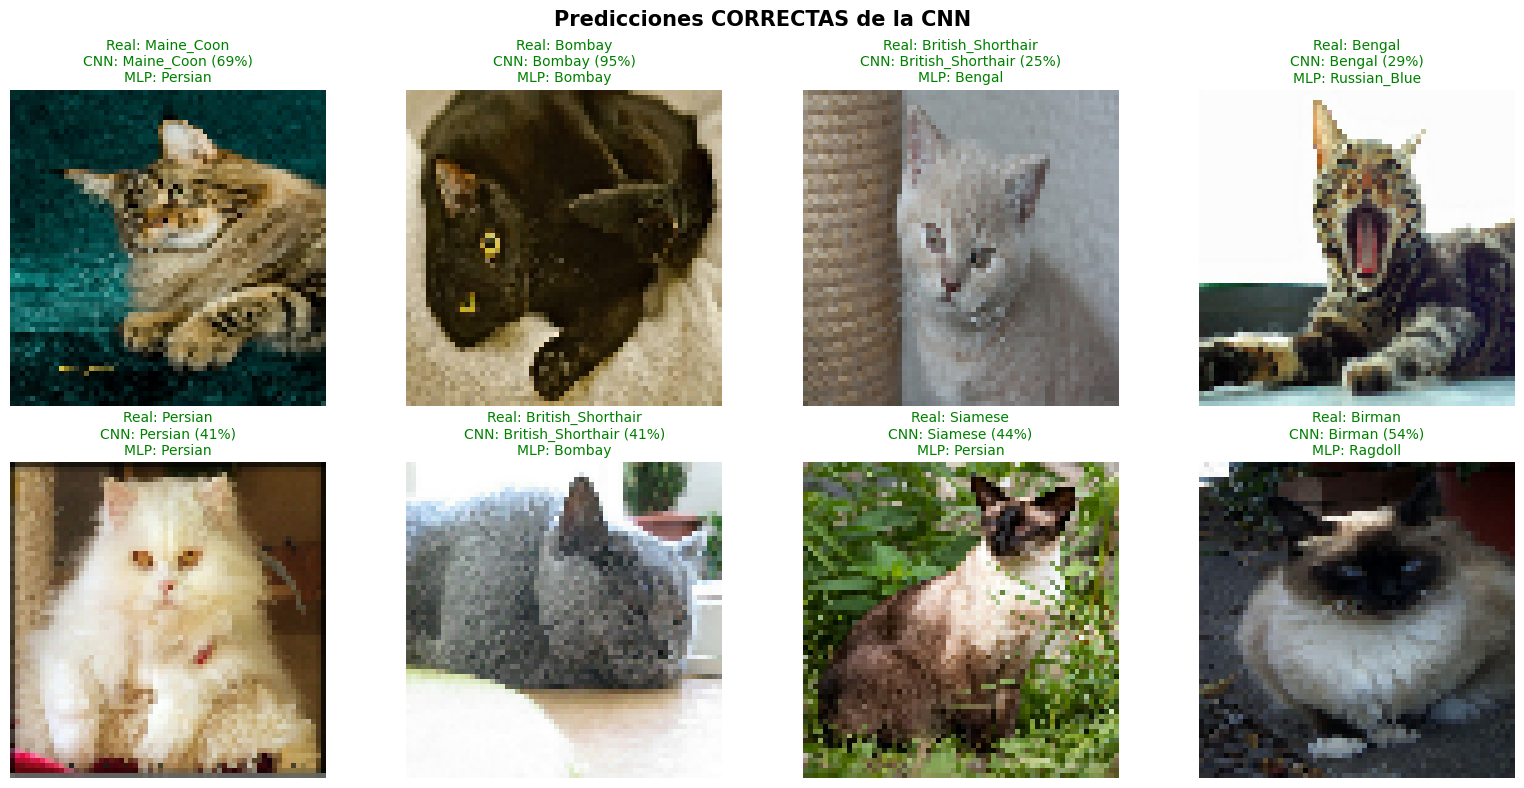

In [59]:

def mostrar_ejemplos(indices, titulo, nombre):
    fig, axs = plt.subplots(2, 4, figsize=(16, 8))
    for ax, i in zip(axs.flat, indices):
        ax.imshow(X_test[i])
        ok = y_pred_cnn[i] == y_test[i]
        ax.set_title(f"Real: {classes[y_test[i]]}\nCNN: {classes[y_pred_cnn[i]]} ({conf_cnn[i]:.0%})\nMLP: {classes[y_pred_mlp[i]]}",
                     fontsize=10, color="green" if ok else "red")
        ax.axis("off")
    plt.suptitle(titulo, fontsize=15, fontweight="bold")
    plt.tight_layout()
    guardar(nombre)
    plt.show()

sel_ok = rng.choice(idx_ok, size=min(8, len(idx_ok)), replace=False)
sel_err = rng.choice(idx_err, size=min(8, len(idx_err)), replace=False)
mostrar_ejemplos(sel_ok, "Predicciones CORRECTAS de la CNN", "08_ejemplos_correctos")

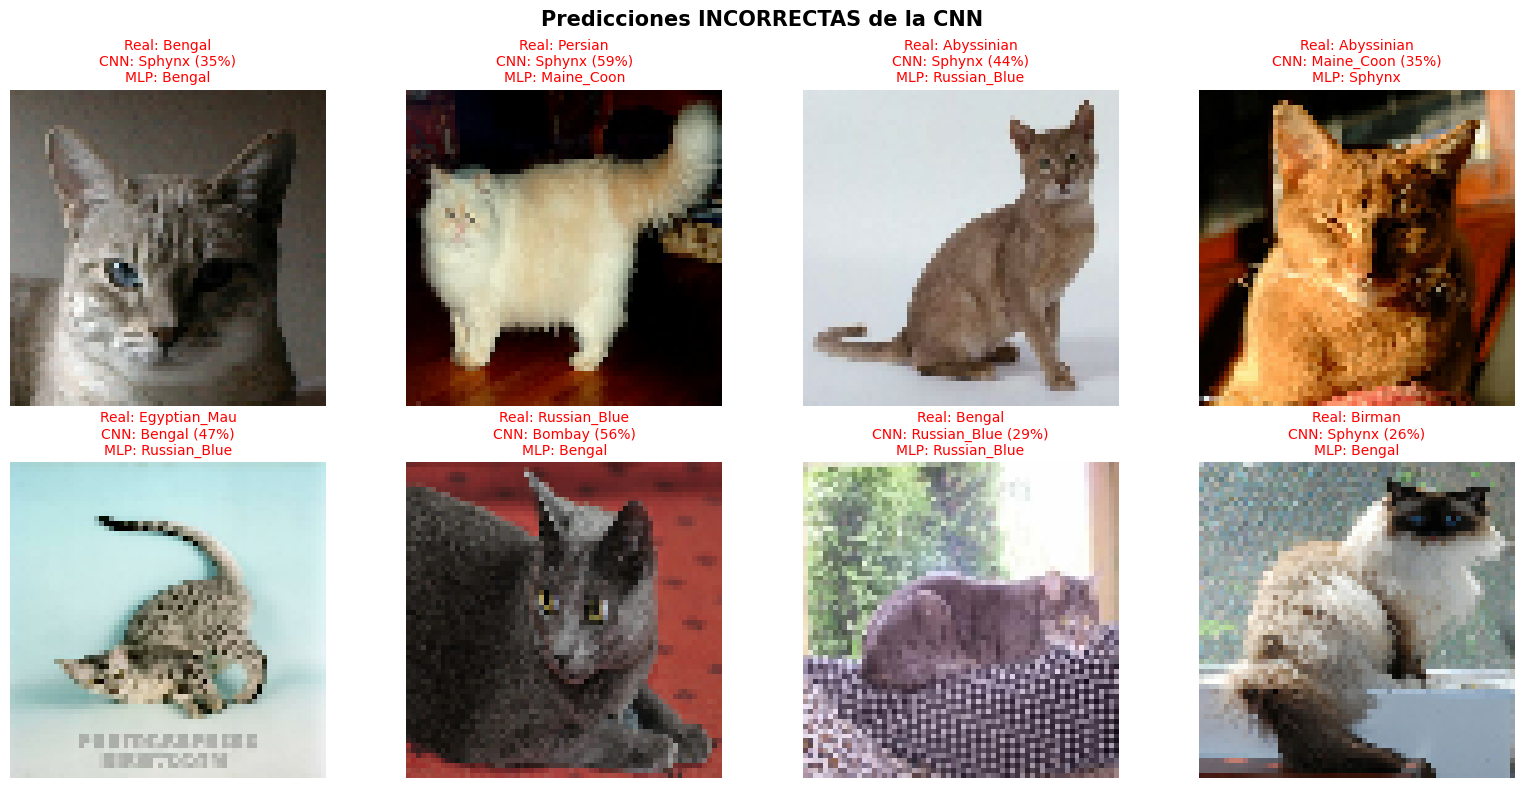

In [60]:
mostrar_ejemplos(sel_err, "Predicciones INCORRECTAS de la CNN", "09_ejemplos_incorrectos")

**Análisis de errores**

- Los errores de la CNN tienden a concentrarse en razas de aspecto similar (patrones de color y pelaje parecidos)
- Compara la confianza media en errores y aciertos si la confianza en los errores sigue siendo alta, el modelo está sobreconfiado, consecuencia típica del sobreajuste sin regularización.
- Algunos errores se explican por la imagen misma: gatos parcialmente ocultos, poses poco comunes, fondos con mucho contenido o baja resolución a 64 × 64.
- **Fortalezas y limitaciones:** el MLP es muy rápido pero no capta forma ni textura locales; la CNN reconoce patrones locales pero, con pocos datos y sin regularización, sobreajusta y su techo queda limitado.

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
CNN -> Precision en el conjunto de prueba: 36.63% | Perdida: 1.92
       Prediccion: Sphynx (38%)
MLP -> Precision en el conjunto de prueba: 19.37% | Pérdida: 2.33
       Prediccion: Sphynx (14%)
Clase real: Sphynx


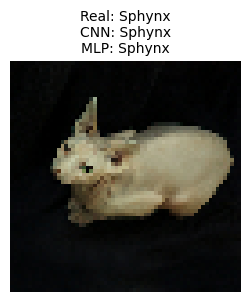

In [61]:
def get_prediction(modelo, X, y, idx):
    probs = modelo.predict(X)
    loss = tf.keras.losses.SparseCategoricalCrossentropy()(y, probs).numpy()
    acc = accuracy_score(y, np.argmax(probs, axis=1))
    return loss, acc, int(np.argmax(probs[idx])), probs[idx]

rng_img = np.random.default_rng(29)
idx = int(rng_img.integers(len(X_test)))

loss_cnn, acc_cnn, pred_cnn, prob_cnn = get_prediction(cnn_model, X_test, y_test, idx)
loss_mlp, acc_mlp, pred_mlp, prob_mlp = get_prediction(mlp_model, X_test, y_test, idx)

print(f"CNN -> Precision en el conjunto de prueba: {acc_cnn * 100:.2f}% | Perdida: {loss_cnn:.2f}")
print(f"       Prediccion: {classes[pred_cnn]} ({prob_cnn[pred_cnn]:.0%})")
print(f"MLP -> Precision en el conjunto de prueba: {acc_mlp * 100:.2f}% | Pérdida: {loss_mlp:.2f}")
print(f"       Prediccion: {classes[pred_mlp]} ({prob_mlp[pred_mlp]:.0%})")
print(f"Clase real: {classes[y_test[idx]]}")

plt.figure(figsize=(3, 3))
plt.imshow(X_test[idx])
plt.title(f"Real: {classes[y_test[idx]]}\nCNN: {classes[pred_cnn]}\nMLP: {classes[pred_mlp]}", fontsize=10)
plt.axis("off")
guardar("10_comparacion_aleatoria")
plt.show()

## 7. Visualización de mapas de características y activación

Observaremos qué representaciones internas crea la CNN y usaremos Grad-CAM (Mapas de Activación Ponderados por Gradiente) para iluminar sobre la imagen original las zonas con las que la red "toma la decisión".


### 7.1 Feature Maps por capa convolucional
Se observan las salidas de las 3 capas convolucionales para una imagen de prueba correctamente clasificada y otra mal clasificada. En cada capa se muestran los 8 mapas con mayor activación media.

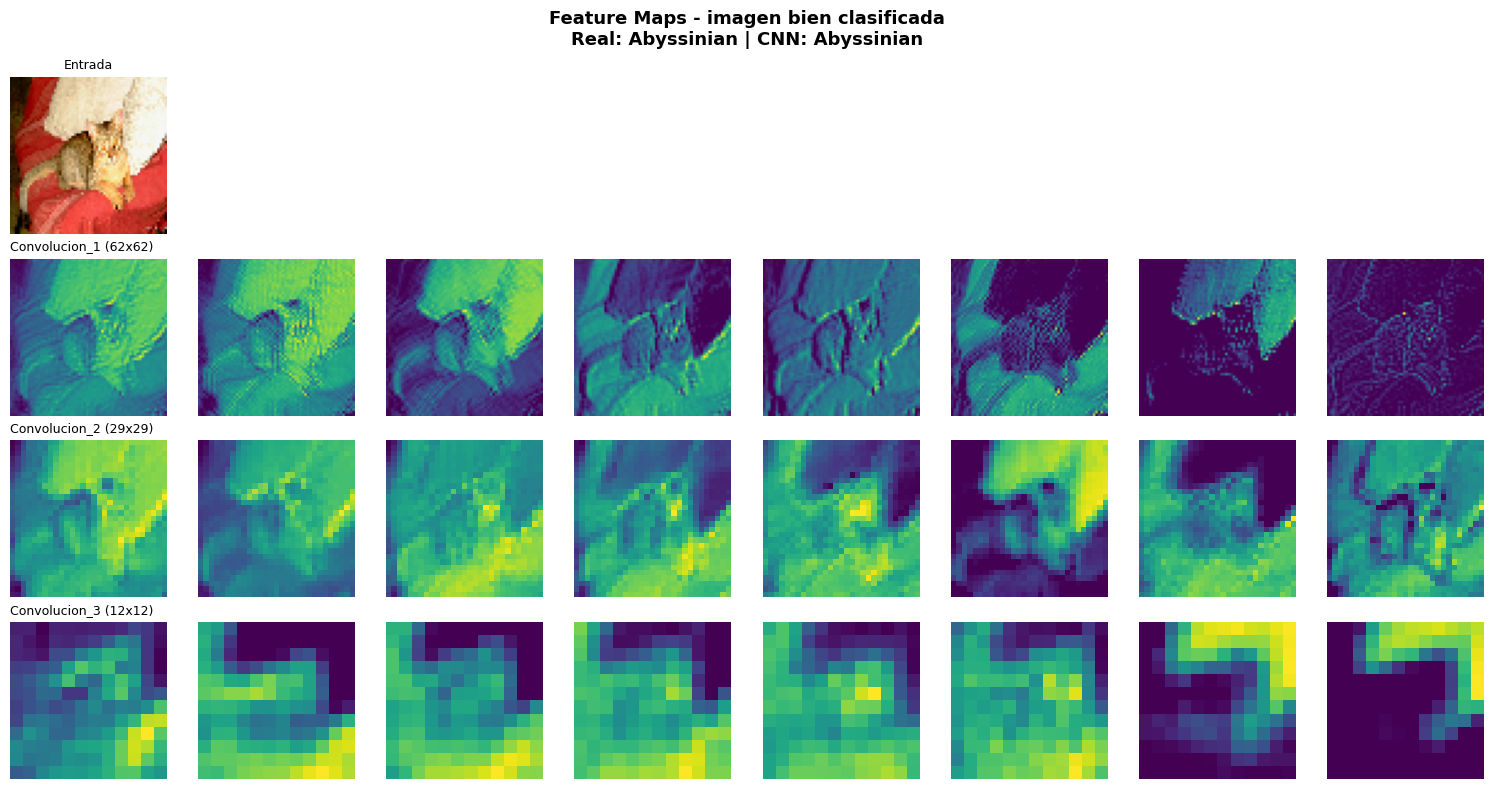

In [62]:
capas_conv = [layer for layer in cnn_model.layers if isinstance(layer, keras.layers.Conv2D)]
modelo_activaciones = keras.models.Model(inputs=cnn_model.inputs[0], outputs=[capa.output for capa in capas_conv])

def graficar_feature_maps(idx, etiqueta, nombre, n_mapas=8):
    img = X_test[idx]
    activaciones = modelo_activaciones.predict(img[np.newaxis], verbose=0)
    fig, axs = plt.subplots(len(capas_conv) + 1, n_mapas, figsize=(n_mapas * 1.9, (len(capas_conv) + 1) * 2.0))
    for ax in axs.flat:
        ax.axis("off")
    axs[0, 0].imshow(img); axs[0, 0].set_title("Entrada", fontsize=9)
    for fila_i, (capa, act) in enumerate(zip(capas_conv, activaciones), start=1):
        act = act[0]
        top = np.argsort(-act.mean(axis=(0, 1)))[:n_mapas]
        for j, f_idx in enumerate(top):
            axs[fila_i, j].imshow(act[:, :, f_idx], cmap="viridis")
        axs[fila_i, 0].set_title(f"{capa.name} ({act.shape[0]}x{act.shape[1]})", fontsize=9, loc="left")
    plt.suptitle(f"Feature Maps - {etiqueta}\nReal: {classes[y_test[idx]]} | CNN: {classes[y_pred_cnn[idx]]}", fontsize=13, fontweight="bold")
    plt.tight_layout()
    guardar(nombre)
    plt.show()

idx_fm_ok = int(idx_ok[0])
idx_fm_err = int(idx_err[0])
graficar_feature_maps(idx_fm_ok, "imagen bien clasificada", "11_feature_maps_correcta")

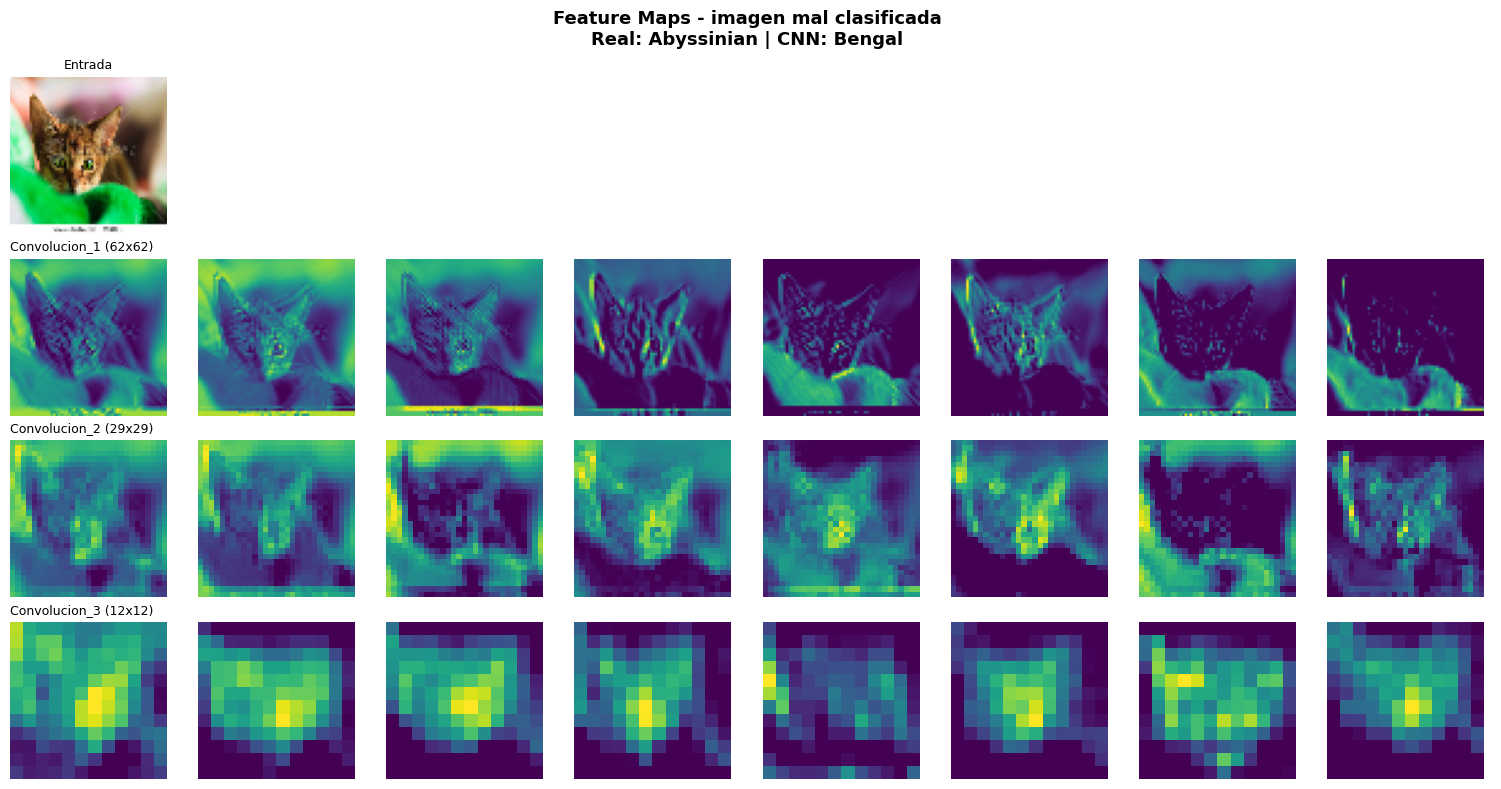

In [63]:
graficar_feature_maps(idx_fm_err, "imagen mal clasificada", "12_feature_maps_incorrecta")

**Interpretación de los Feature Maps (a mayor profundidad)**

| Capa | Resolución | Qué se observa |
|---|---|---|
| **Convolucion_1** (16 filtros) | 62 × 62 | Mapas casi tan detallados como la imagen: responden a bordes, contrastes, líneas y regiones de color. La silueta del gato aún se reconoce. |
| **Convolucion_2** (32 filtros) | 29 × 29 | Combinan bordes en texturas y contornos (pelaje, límites de orejas y cabeza). Empiezan a separar al gato del fondo. |
| **Convolucion_3** (64 filtros) | 12 × 12 | Mapas más borrosos y abstractos: se activan sobre regiones con significado (cabeza, ojos, zonas de pelaje) y no sobre píxeles individuales; es la información que, tras 3 pooling (6 × 6), recibe el clasificador denso. |

**Conclusión:** a medida que aumenta la profundidad crece la abstracción y disminuye la resolución espacial: se pasa de rasgos locales simples a representaciones más semánticas. Esta extracción automática y jerárquica es el aporte central de las capas convolucionales y es lo que el MLP no puede hacer al aplanar la imagen.

### 7.2 Mapas de activación (Grad-CAM) por clase
Grad-CAM pondera los mapas de la última capa convolucional con el gradiente de la clase objetivo y resalta (rojo/amarillo) las zonas que más contribuyen a la decisión. Para cada una de las 12 razas se toma una imagen de prueba (preferentemente bien clasificada) y se calcula el mapa respecto de la clase real.

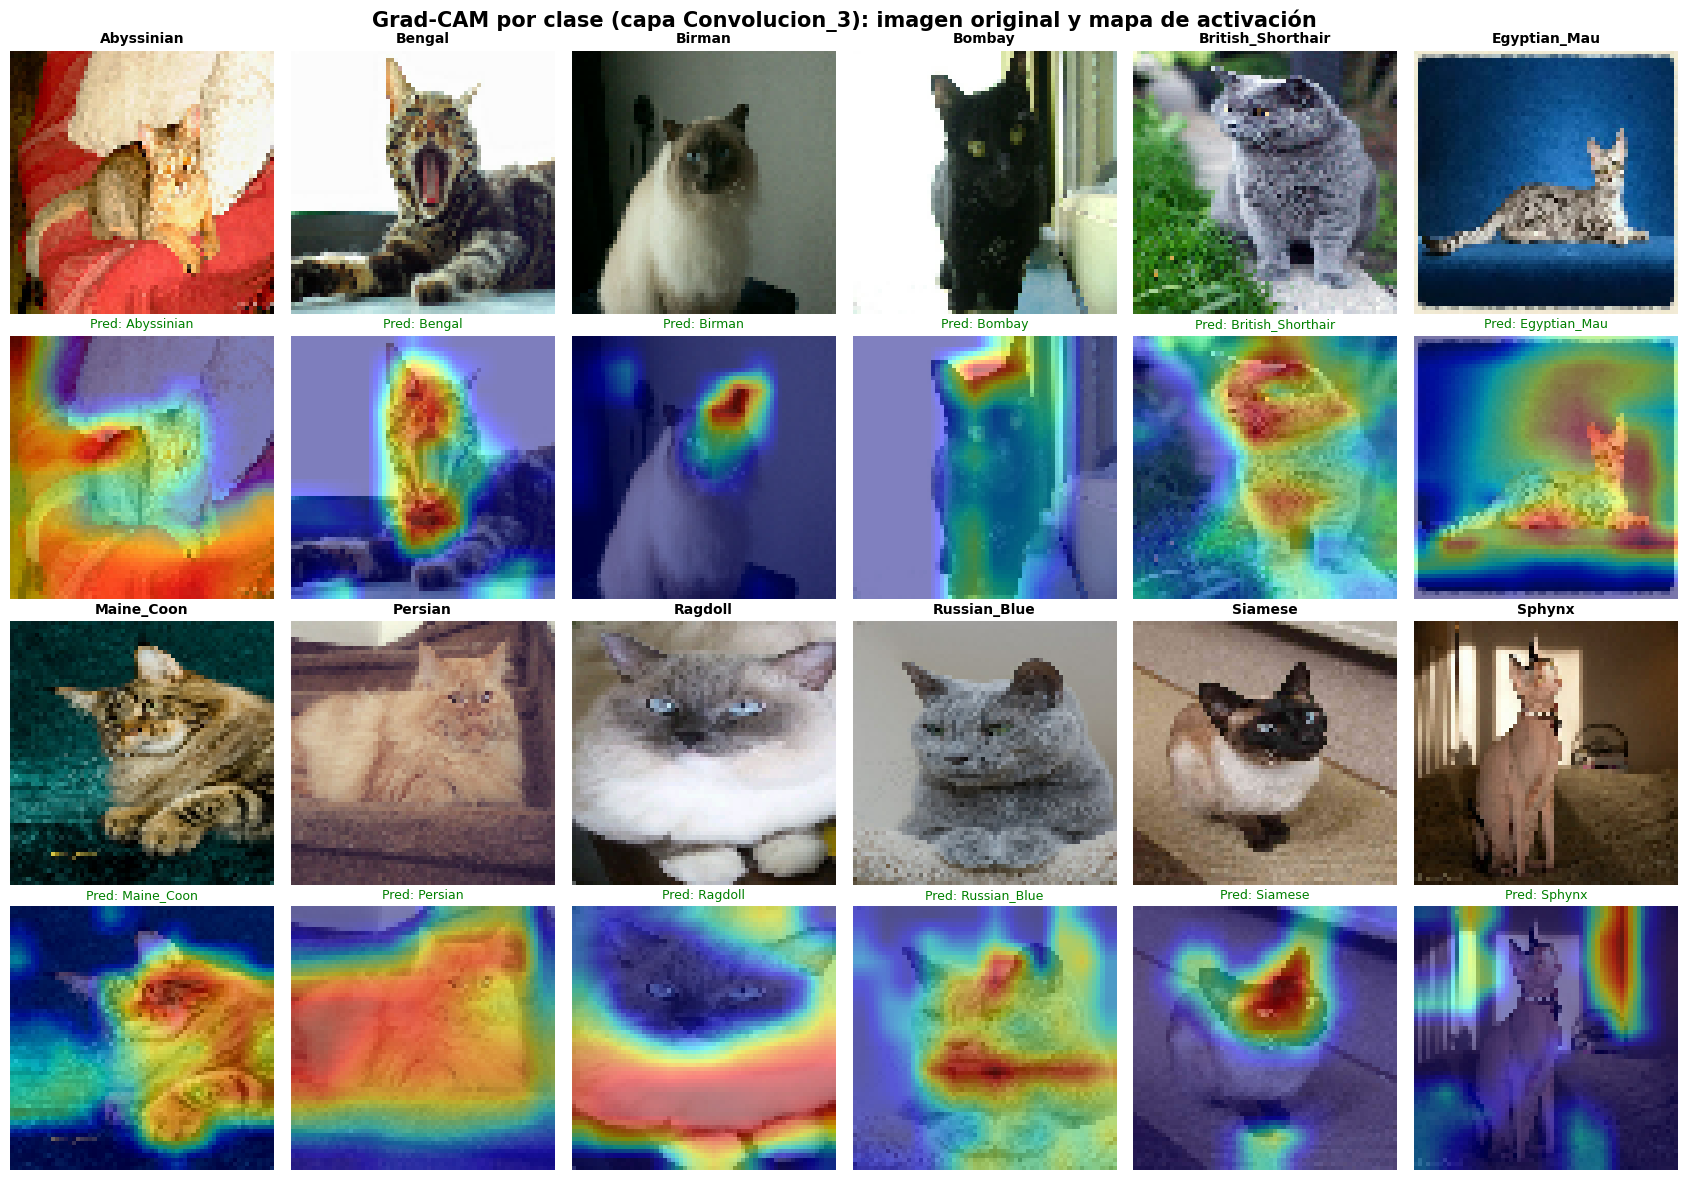

In [64]:
def generar_gradcam(model, img, clase_idx, capa_nombre):
    img_tensor = tf.convert_to_tensor(np.expand_dims(img, axis=0), dtype=tf.float32)
    grad_model = keras.models.Model(
        inputs=[model.inputs[0]],
        outputs=[model.get_layer(capa_nombre).output, model.outputs[0]]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_tensor)
        loss = predictions[:, clase_idx]

    grads = tape.gradient(loss, conv_outputs)
    pesos = tf.reduce_mean(grads, axis=(1, 2))

    conv_outputs = conv_outputs[0]
    cam = tf.reduce_sum(tf.multiply(pesos, conv_outputs), axis=-1)
    cam = tf.maximum(cam, 0)
    cam /= tf.math.reduce_max(cam) + 1e-8
    cam = tf.image.resize(cam[..., tf.newaxis], IMG_SIZE).numpy()[..., 0]
    return cam

ultima_capa_conv = capas_conv[-1].name

idx_por_clase = []
for c in range(NUM_CLASSES):
    cand = np.where(y_test == c)[0]
    ok = [i for i in cand if y_pred_cnn[i] == c]
    idx_por_clase.append(int(ok[0] if ok else cand[0]))

fig, axs = plt.subplots(4, 6, figsize=(17, 12))
for c, idx in enumerate(idx_por_clase):
    bloque, col = divmod(c, 6)
    cam = generar_gradcam(cnn_model, X_test[idx], c, ultima_capa_conv)
    axs[bloque * 2, col].imshow(X_test[idx]); axs[bloque * 2, col].axis("off")
    axs[bloque * 2, col].set_title(classes[c], fontsize=10, fontweight="bold")
    axs[bloque * 2 + 1, col].imshow(X_test[idx])
    axs[bloque * 2 + 1, col].imshow(cam, cmap="jet", alpha=0.5)
    acierto = y_pred_cnn[idx] == c
    axs[bloque * 2 + 1, col].set_title(f"Pred: {classes[y_pred_cnn[idx]]}", fontsize=9, color="green" if acierto else "red")
    axs[bloque * 2 + 1, col].axis("off")
plt.suptitle(f"Grad-CAM por clase (capa {ultima_capa_conv}): imagen original y mapa de activación", fontsize=15, fontweight="bold")
plt.tight_layout()
guardar("13_gradcam_por_clase")
plt.show()

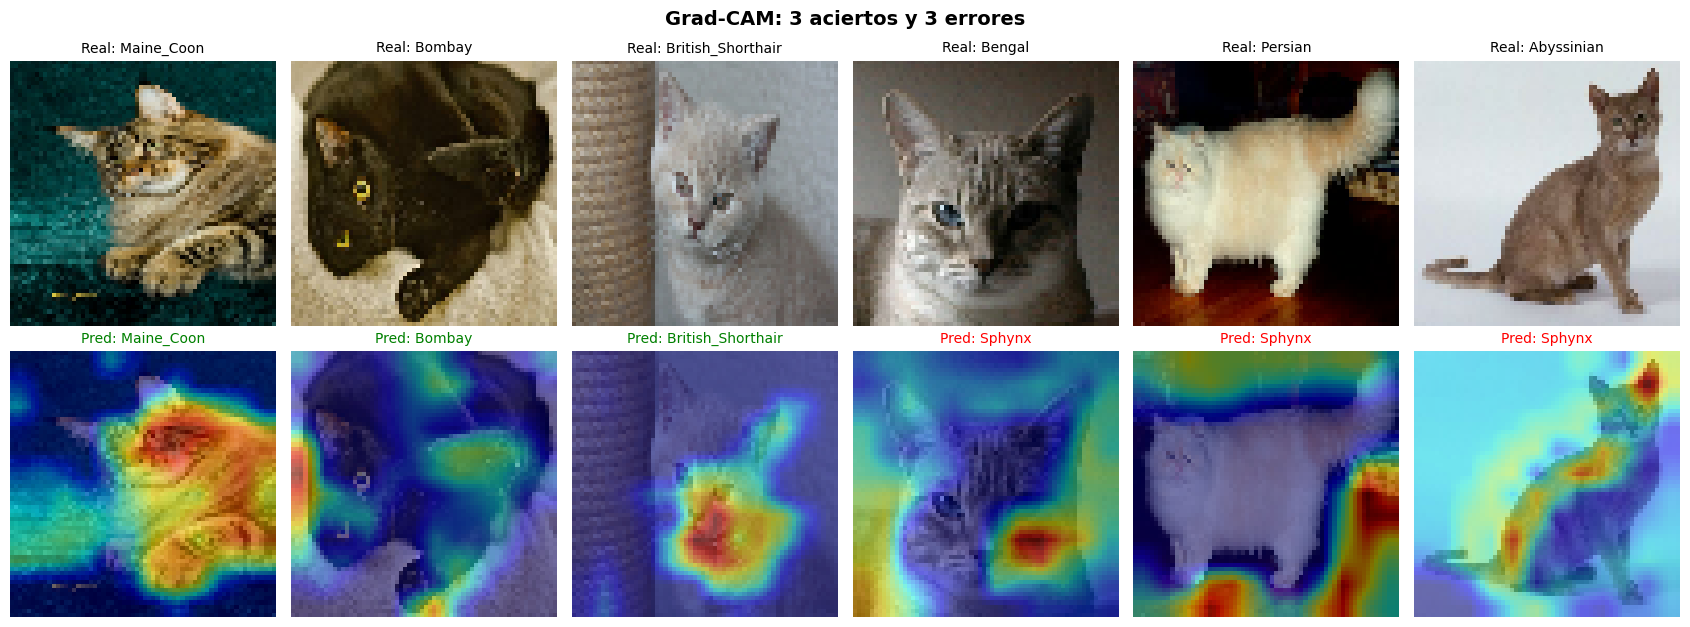

In [65]:

fig, axs = plt.subplots(2, 6, figsize=(17, 6.5))
muestras = list(sel_ok[:3]) + list(sel_err[:3])
for col, idx in enumerate(muestras):
    cam = generar_gradcam(cnn_model, X_test[idx], int(y_pred_cnn[idx]), ultima_capa_conv)
    ok = y_pred_cnn[idx] == y_test[idx]
    axs[0, col].imshow(X_test[idx]); axs[0, col].axis("off")
    axs[0, col].set_title(f"Real: {classes[y_test[idx]]}", fontsize=10)
    axs[1, col].imshow(X_test[idx]); axs[1, col].imshow(cam, cmap="jet", alpha=0.5); axs[1, col].axis("off")
    axs[1, col].set_title(f"Pred: {classes[y_pred_cnn[idx]]}", fontsize=10, color="green" if ok else "red")
plt.suptitle("Grad-CAM: 3 aciertos y 3 errores", fontsize=14, fontweight="bold")
plt.tight_layout()
guardar("14_gradcam_aciertos_vs_errores")
plt.show()

**Interpretación de Grad-CAM**

- En las imágenes bien clasificadas el mapa de calor debería concentrarse sobre el cuerpo y la cabeza del gato (pelaje, rostro), que es la región informativa para la raza.
- En los errores conviene comprobar si el calor aparece desplazado hacia el fondo, objetos o bordes, o repartido de forma difusa: eso indicaría que el modelo basó su decisión en información poco relevante (sesgo contextual del dataset).
- La última capa convolucional (Convolucion_3) tiene 12 × 12 celdas, por lo que los mapas son gruesos (se reescalan a 64 × 64); sirven para ubicar la región general, no el contorno exacto.
- Estas lecturas deben contrastarse con las figuras de la ejecución antes de exponerlas, ya que las imágenes mostradas cambian con cada entrenamiento.

In [66]:
print("================ RESUMEN DE RESULTADOS ================")
print(f"CNN    -> Acc: {met_cnn['accuracy']:.3f} | F1 macro: {met_cnn['f1_macro']:.3f} | Parametros: {cnn_model.count_params():,} | Epocas: {n_ep_cnn} | Tiempo: {t_cnn:.0f} s")
print(f"MLP    -> Acc: {met_mlp['accuracy']:.3f} | F1 macro: {met_mlp['f1_macro']:.3f} | Parametros: {mlp_model.count_params():,} | Epocas: {EPOCAS_MLP_E1} | Tiempo: {TIEMPO_MLP_E1_S:.0f} s")
print(f"Mejora de accuracy CNN vs MLP: {(met_cnn['accuracy'] - met_mlp['accuracy'])*100:+.1f} puntos porcentuales")
print(f"Reducción de parámetros: {(1 - cnn_model.count_params()/mlp_model.count_params())*100:.0f} %")
print(f"Brecha train-test -> CNN: {acc_cnn_train - met_cnn['accuracy']:.3f} | MLP: {acc_mlp_train - met_mlp['accuracy']:.3f}")

resultados = {"cnn": {**met_cnn, "params": int(cnn_model.count_params()), "epocas": int(n_ep_cnn), "tiempo_s": round(t_cnn, 1)},
              "mlp_e1": {**met_mlp, "params": int(mlp_model.count_params()), "epocas": EPOCAS_MLP_E1, "tiempo_s": TIEMPO_MLP_E1_S}}
with open(f"{IMAGES_DIR}/resultados.json", "w") as f:
    json.dump(resultados, f, indent=2)

================ RESUMEN DE RESULTADOS ================
CNN    -> Acc: 0.366 | F1 macro: 0.354 | Parametros: 320,172 | Epocas: 10 | Tiempo: 10 s
MLP    -> Acc: 0.194 | F1 macro: 0.156 | Parametros: 1,582,028 | Epocas: 30 | Tiempo: 11 s
Mejora de accuracy CNN vs MLP: +17.3 puntos porcentuales
Reducción de parámetros: 80 %
Brecha train-test -> CNN: 0.098 | MLP: 0.054


## 8. Conclusiones y Matriz de Responsabilidades

1. **Desempeño arquitectónico (CNN vs MLP):** evaluadas sobre el mismo conjunto de prueba, la CNN supera al MLP de la Evaluación 1 en Accuracy, Precision, Recall y F1. La causa es arquitectónica: la CNN conserva la estructura espacial y reutiliza filtros en toda la imagen, en vez de aplanarla desde el inicio.
2. **Eficiencia:** la CNN logra ese mejor desempeño con muchos menos parámetros que el MLP, a cambio de un mayor costo de cómputo por época.
3. **Sobreajuste:** con alrededor de 1.500 imágenes y 12 clases , ambos modelos rinden menos en prueba que en entrenamiento. EarlyStopping limita el sobreajuste de la CNN al detener el entrenamiento en la mejor época, pero no lo elimina.
4. **Validación del MLP:** la validación de la Evaluación 1 estaba contaminada porque se creó con `shuffle=False`, lo que solapaba validación y entrenamiento. Con la validación corregida, el MLP obtiene 0,216 de accuracy y la CNN 0,325. La comparación válida entre ambos modelos es la del conjunto de prueba.
5. **Errores e interpretabilidad:** los errores tienden a concentrarse en razas visualmente similares. Los Feature Maps muestran la jerarquía bordes → texturas → regiones con significado, y Grad-CAM permite auditar en qué zonas se apoya cada decisión y detectar posibles sesgos de contexto (fondos, objetos).
6. **Trabajo futuro:** aumentar la resolución de entrada (128 × 128) y evaluar data augmentation y transfer learning.

---

### Matriz de Responsabilidades

| Integrante | Tareas Realizadas |
|---|---|
| **Agustín Fernández** | Preparación de datos, lógica de extracción de Dataset, validación de normalización y EDA. |
| **Sebastián Salgado** | Diseño e implementación de arquitectura CNN, visualización de Feature Maps. |
| **Eduardo Uribe** | Entrenamiento, evaluación comparativa CNN vs MLP (E1), análisis Grad-CAM y redacción final. |